# 1 · Fashion-MNIST with an MLP

Train an MLP on ten clothing classes. Inspect its errors. Change its settings.

## Setup

In [1]:
import os, re, time, math, random
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import torchvision
from torch.utils.data import DataLoader, TensorDataset
from torchvision import transforms
from PIL import Image
from sklearn.metrics import roc_auc_score

QUICK = True
SEED  = 42
IMAGE_SIZE = 28

random.seed(SEED); np.random.seed(SEED)
torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DATA_DIR = Path("/content/data") if Path("/content").is_dir() else Path("./data")
DATA_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams["figure.dpi"] = 100
print("device :", device)
print("QUICK  :", QUICK)
if device.type == "cuda": print("gpu    :", torch.cuda.get_device_name(0))


device : cuda
QUICK  : True
gpu    : Tesla T4


In [2]:
@torch.no_grad()
def accuracy(model, X, y, batch_size=256):
    model.eval()
    correct = 0
    for i in range(0, len(X), batch_size):
        pred = model(X[i:i+batch_size].to(device)).argmax(1).cpu()
        correct += (pred == y[i:i+batch_size]).sum().item()
    return correct / len(X)

@torch.no_grad()
def auc(model, X, y, batch_size=256):
    """Macro one-vs-rest AUC. Threshold-free ranking quality."""
    model.eval()
    ps = []
    for i in range(0, len(X), batch_size):
        ps.append(torch.softmax(model(X[i:i+batch_size].to(device)), 1).cpu())
    return roc_auc_score(y.numpy(), torch.cat(ps).numpy(), multi_class="ovr")


def n_params(model):
    return sum(p.numel() for p in model.parameters())

def train(model, X, y, epochs=10, lr=1e-3, batch_size=64, X_val=None, y_val=None,
          criterion=None, weight_decay=0.0, log=True):

    loader = DataLoader(TensorDataset(X, y), batch_size=batch_size, shuffle=True)
    criterion = criterion or nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    history = {"train_loss": [], "train_acc": [], "val_acc": []}

    for epoch in range(epochs):
        t0 = time.time()
        model.train()
        total, correct, running = 0, 0, 0.0
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)

            optimizer.zero_grad()          # 1. forget the gradients of the previous batch
            out  = model(xb)               # 2. forward pass -> raw scores (logits)
            loss = criterion(out, yb)      # 3. calculate the loss
            loss.backward()                # 4. backprop: fill .grad for every weight
            optimizer.step()               # 5. nudge every weight downhill

            running += loss.item() * xb.size(0)
            correct += (out.argmax(1) == yb).sum().item()
            total   += xb.size(0)

        history["train_loss"].append(running / total)
        history["train_acc"].append(correct / total)

        if X_val is not None:
            history["val_acc"].append(accuracy(model, X_val, y_val))
        if log:
            msg = f"epoch {epoch+1}/{epochs} | train loss {running/total:.4f} | train acc {correct/total:.3f}"
            if X_val is not None:
                msg += f" | val acc {history['val_acc'][-1]:.3f}"
            print(msg + f" | {time.time()-t0:.1f}s")

    return history


def plot_history(history, title=""):
    fig, axes = plt.subplots(1, 2, figsize=(9, 3))
    axes[0].plot(history["train_loss"])
    axes[0].set_xlabel("epoch"); axes[0].set_ylabel("loss"); axes[0].set_title("training loss")
    axes[1].plot(history["train_acc"], label="train")
    if history["val_acc"]:
        axes[1].plot(history["val_acc"], label="val")
    axes[1].set_xlabel("epoch"); axes[1].set_ylabel("accuracy"); axes[1].set_ylim(0, 1)
    axes[1].set_title("train vs validation accuracy"); axes[1].legend()
    if title:
        fig.suptitle(title)
    plt.tight_layout(); plt.show()


def show_images(images, titles=None, ncols=5, title=None):
    n = len(images)
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 1.7, nrows * 1.9))
    axes = np.atleast_1d(axes).ravel()
    for ax in axes:
        ax.axis("off")
    for i, img in enumerate(images):
        arr = img.detach().cpu().permute(1, 2, 0).clamp(0, 1).numpy()
        if arr.shape[2] == 1:
            arr = arr[..., 0]
        axes[i].imshow(arr)
        if titles is not None:
            axes[i].set_title(titles[i], fontsize=8)
    if title:
        fig.suptitle(title)
    plt.tight_layout(); plt.show()


## 1. The data

[Fashion-MNIST](https://github.com/zalandoresearch/fashion-mnist) has ten clothing classes.
It has 60,000 training images and 10,000 test images. Images are 28×28 pixels.

The classes are well balanced. Chance accuracy is 0.10.

We standardise pixels with the training-set mean and standard deviation. `ToTensor()` already scales
pixels to [0, 1]. Standardisation helps the optimiser.

In [3]:
# ---------------------------------------------------------------------------
# Fashion-MNIST via torchvision: 10 clothing classes
# ---------------------------------------------------------------------------

CLASS_NAMES = ["T-shirt", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
N_CLASSES = len(CLASS_NAMES)


def load_fashion(size=IMAGE_SIZE):
    tf = transforms.Compose([transforms.Resize((size, size)), transforms.ToTensor()])
    train_base = torchvision.datasets.FashionMNIST(str(DATA_DIR), train=True, download=True, transform=tf)
    test_base = torchvision.datasets.FashionMNIST(str(DATA_DIR), train=False, download=True, transform=tf)

    def to_tensor(ds, limit):
        n = len(ds) if limit is None else min(limit, len(ds))
        X = torch.empty(n, 1, size, size)
        y = torch.empty(n, dtype=torch.long)
        for i in range(n):
            xi, yi = ds[i]
            X[i], y[i] = xi, yi
            if (i + 1) % 4000 == 0:
                print(f"  decoded {i+1}/{n}")
        return X, y

    X_tr_all, y_tr_all  = to_tensor(train_base, 8_000 if QUICK else None)
    X_te, y_te          = to_tensor(test_base, 2_000 if QUICK else None)
    return X_tr_all, y_tr_all, X_te, y_te

100%|██████████| 26.4M/26.4M [00:02<00:00, 10.1MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 168kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.10MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 23.7MB/s]


  decoded 4000/8000
  decoded 8000/8000
train 7200 | val 800 | test 2000
'always answer t-shirt' scores 0.10 on the test set -> this is our accuracy baseline
one image tensor: (1, 28, 28), values roughly in [-2, 2]


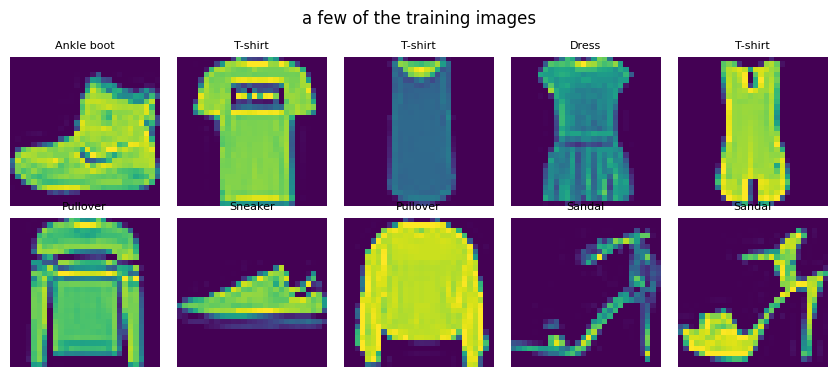

In [4]:
X_tr_all, y_tr_all, X_te, y_te = load_fashion()

# train/validation split
g = torch.Generator().manual_seed(SEED)
perm = torch.randperm(len(X_tr_all), generator=g)
n_val = int(0.1 * len(perm))
val_idx, train_idx = perm[:n_val], perm[n_val:]

# standardise with statistics from the training set only
mu = X_tr_all[train_idx].mean(dim=(0, 2, 3), keepdim=True)
sd = X_tr_all[train_idx].std(dim=(0, 2, 3), keepdim=True)
norm = lambda z: (z - mu) / sd

X     = norm(X_tr_all[train_idx]); y     = y_tr_all[train_idx]
X_val = norm(X_tr_all[val_idx]);   y_val = y_tr_all[val_idx]
X_test, y_test = norm(X_te), y_te

print(f"train {len(X)} | val {len(X_val)} | test {len(X_test)}")
print(f"'always answer t-shirt' scores {(y_te == 0).float().mean().item():.2f} on the test set -> this is our accuracy baseline")
print(f"one image tensor: {tuple(X[0].shape)}, values roughly in [-2, 2]")

show_images([X_tr_all[i] for i in range(10)],
            titles=[CLASS_NAMES[int(y_tr_all[i])] for i in range(10)],
            ncols=5, title="a few of the training images")

## 2. The model and the loop

The MLP receives 4,096 pixel values. It treats each pixel as a separate input.
It has no built-in information about neighbouring pixels.

In [5]:
model = nn.Sequential(
    nn.Flatten(),
    nn.Linear(1 * IMAGE_SIZE * IMAGE_SIZE, 256),
    nn.ReLU(),
    nn.Linear(256, N_CLASSES),
).to(device)

print(model)
print(f"\n{n_params(model):,} trainable parameters")

Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=784, out_features=256, bias=True)
  (2): ReLU()
  (3): Linear(in_features=256, out_features=10, bias=True)
)

203,530 trainable parameters


Train for ten epochs.

epoch 1/10 | train loss 0.6686 | train acc 0.761 | val acc 0.838 | 0.6s
epoch 2/10 | train loss 0.4527 | train acc 0.838 | val acc 0.850 | 0.2s
epoch 3/10 | train loss 0.4190 | train acc 0.845 | val acc 0.848 | 0.3s
epoch 4/10 | train loss 0.3552 | train acc 0.871 | val acc 0.810 | 0.3s
epoch 5/10 | train loss 0.3359 | train acc 0.878 | val acc 0.845 | 0.3s
epoch 6/10 | train loss 0.3102 | train acc 0.886 | val acc 0.844 | 0.2s
epoch 7/10 | train loss 0.2714 | train acc 0.902 | val acc 0.865 | 0.2s
epoch 8/10 | train loss 0.2482 | train acc 0.908 | val acc 0.864 | 0.2s
epoch 9/10 | train loss 0.2349 | train acc 0.911 | val acc 0.849 | 0.2s
epoch 10/10 | train loss 0.2162 | train acc 0.919 | val acc 0.845 | 0.2s


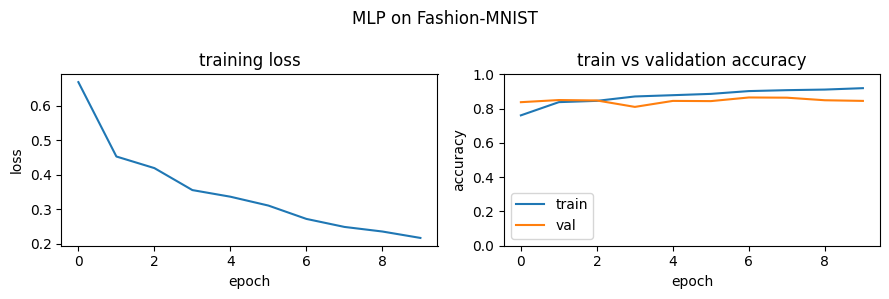

In [ ]:
history = train(model, X, y, epochs=10, lr=1e-3, X_val=X_val, y_val=y_val)
plot_history(history, "MLP on Fashion-MNIST")

## 3. Evaluate the model

test accuracy : 0.853   (chance level: 0.10)
AUC (macro)   : 0.987   (0.5 = no ranking signal)

per-class recall, worst first:
  Shirt        0.726   (197 images)
  T-shirt      0.730   (200 images)
  Coat         0.753   (219 images)
  Pullover     0.762   (214 images)
  Sandal       0.872   (195 images)
  Dress        0.916   (190 images)
  Bag          0.928   (194 images)
  Ankle boot   0.936   (188 images)
  Trouser      0.946   (203 images)
  Sneaker      0.980   (200 images)


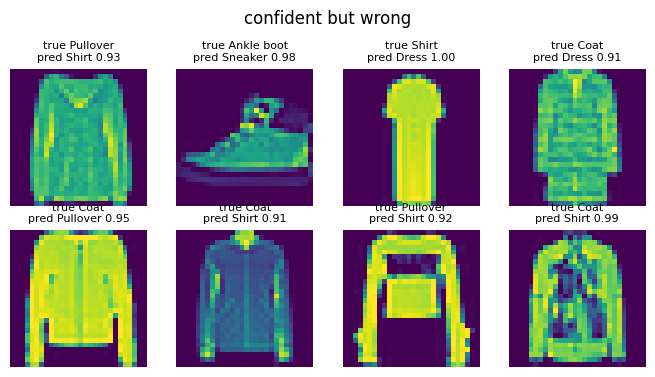

In [7]:
with torch.no_grad():
    logits = model(X_test.to(device))
probs = torch.softmax(logits, 1).cpu()
pred = probs.argmax(1)
conf = probs.max(1).values

print(f"test accuracy : {(pred == y_test).float().mean():.3f}   (chance level: {1 / N_CLASSES:.2f})")
print(f"AUC (macro)   : {auc(model, X_test, y_test):.3f}   (0.5 = no ranking signal)")

recalls = []
for c, name in enumerate(CLASS_NAMES):
    m = y_test == c
    recalls.append(((pred[m] == c).float().mean().item(), name, int(m.sum())))
recalls.sort()
print("\nper-class recall, worst first:")
for r, name, n in recalls:
    print(f"  {name:<12} {r:.3f}   ({n} images)")

wrong = ((pred != y_test) & (conf > 0.90)).nonzero().flatten()[:8].tolist()
if wrong:
    show_images([X_te[i] for i in wrong],
                titles=[f"true {CLASS_NAMES[int(y_test[i])]}\npred {CLASS_NAMES[int(pred[i])]} {conf[i]:.2f}"
                        for i in wrong],
                ncols=4, title="confident but wrong")

## 4. Regularisation

`make_mlp` sets the number and size of hidden layers. It also sets dropout and batch normalisation.
The next cell compares regularised models with the default model.

In [8]:
def make_mlp(hidden=(256,), dropout=0.0, batchnorm=False):
    layers = [nn.Flatten()]
    in_features = 1 * IMAGE_SIZE * IMAGE_SIZE
    for h in hidden:
        layers.append(nn.Linear(in_features, h))
        if batchnorm:
            layers.append(nn.BatchNorm1d(h))
        layers.append(nn.ReLU())
        if dropout:
            layers.append(nn.Dropout(dropout))
        in_features = h
    layers.append(nn.Linear(in_features, N_CLASSES))
    return nn.Sequential(*layers).to(device)

def stats(m):
    with torch.no_grad():
        pm = torch.softmax(m(X_test.to(device)), 1).argmax(1).cpu()
    recalls = [(pm[y_test == c] == c).float().mean().item() for c in range(N_CLASSES)]
    return ((pm == y_test).float().mean().item(),
            auc(m, X_test, y_test),
            min(recalls))

rows = [("plain (from above)", history["train_acc"][-1], *stats(model))]
for name, p_drop, wd in [("dropout 0.5", 0.5, 0.0), ("dropout + wd 1e-2", 0.5, 1e-2)]:
    m = make_mlp(dropout=p_drop)
    h = train(m, X, y, epochs=10, lr=1e-3, weight_decay=wd, log=False)
    rows.append((name, h["train_acc"][-1], *stats(m)))

print(f"{'model':<22}{'train':>8}{'test':>8}{'AUC':>7}{'min recall':>12}")
for name, tr, te, a, cat in rows:
    print(f"{name:<22}{tr:>8.3f}{te:>8.3f}{a:>7.3f}{cat:>12.3f}")
print(f"{'chance level':<22}{'-':>8}{1 / N_CLASSES:>8.3f}")

model                    train    test    AUC  min recall
plain (from above)       0.919   0.853  0.987       0.726
dropout 0.5              0.873   0.841  0.987       0.563
dropout + wd 1e-2        0.818   0.795  0.984       0.498
chance level                 -   0.100


## 5. Which classes does it confuse?

The heatmap shows true classes by row and predictions by column. Colour shows the fraction of each class. Numbers show counts.

most confused pairs (true -> predicted):
  T-shirt    -> Shirt      29
  Pullover   -> Shirt      26
  Coat       -> Shirt      22
  Coat       -> Pullover   21
  Sandal     -> Sneaker    20
  Pullover   -> Coat       20


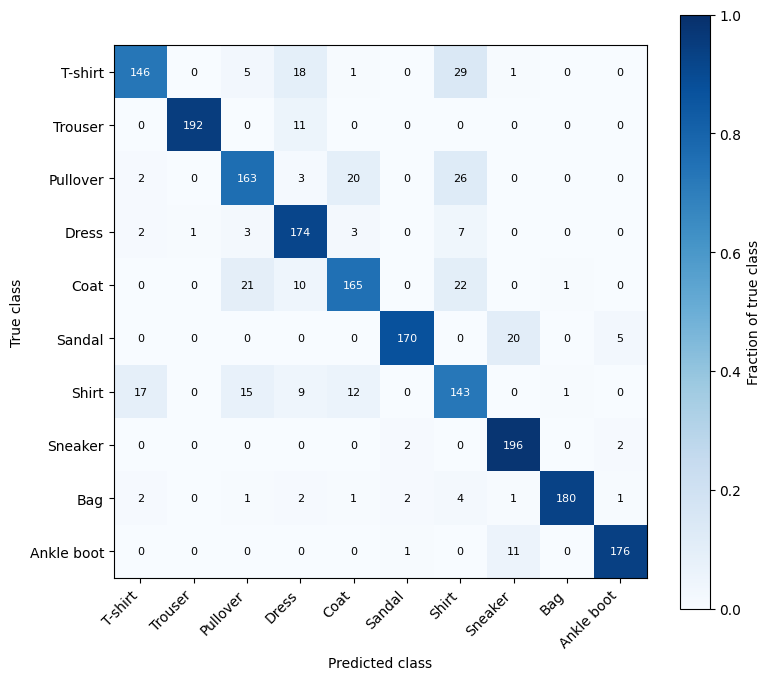

In [9]:
cm = torch.zeros(N_CLASSES, N_CLASSES, dtype=torch.long)
for t, p in zip(y_test.tolist(), pred.tolist()):
    cm[t, p] += 1

pairs = []
for t in range(N_CLASSES):
    for p in range(N_CLASSES):
        if t != p and cm[t, p] > 0:
            pairs.append((int(cm[t, p]), t, p))
pairs.sort(reverse=True)

print("most confused pairs (true -> predicted):")
for n, t, p in pairs[:6]:
    print(f"  {CLASS_NAMES[t]:<10} -> {CLASS_NAMES[p]:<10} {n}")

# Colour shows the fraction of each true class. Numbers show counts.
row_totals = cm.sum(dim=1, keepdim=True).clamp_min(1)
cm_fraction = cm.float() / row_totals
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(cm_fraction.numpy(), cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(N_CLASSES), CLASS_NAMES, rotation=45, ha="right")
ax.set_yticks(range(N_CLASSES), CLASS_NAMES)
ax.set_xlabel("Predicted class")
ax.set_ylabel("True class")
fig.colorbar(im, ax=ax, label="Fraction of true class")
for r in range(N_CLASSES):
    for c in range(N_CLASSES):
        color = "white" if cm_fraction[r, c] > 0.5 else "black"
        ax.text(c, r, str(cm[r, c].item()), ha="center", va="center", color=color, fontsize=8)
plt.tight_layout(); plt.show()


Most errors are between similar classes: Pullover and Coat, T-shirt and Shirt.

## 6. Playground

Use `run_config` to train another MLP. Each call adds a row and updates the chart.
Red line: chance accuracy (0.10). Grey line: chance AUC (0.50).

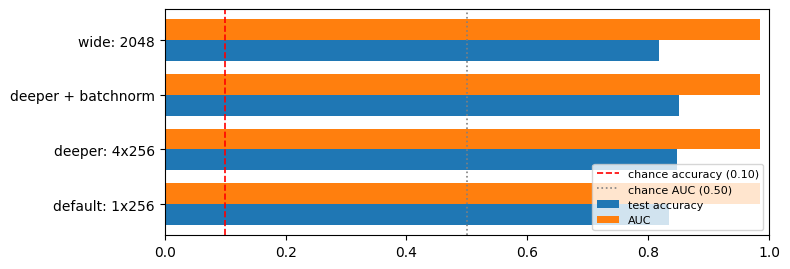

model                              params   train    test    AUC  min recall
default: 1x256                    203,530   0.917   0.835  0.986       0.579
deeper: 4x256                     400,906   0.907   0.849  0.986       0.720
deeper + batchnorm                402,954   0.923   0.850  0.985       0.711
wide: 2048                      1,628,170   0.927   0.818  0.985       0.589


In [10]:
results = []


def run_config(name, hidden=(256,), dropout=0.0, batchnorm=False,
               weight_decay=0.0, lr=1e-3, epochs=10, show=True):
    """Train one configuration, score it, add a row, redraw the picture."""
    m = make_mlp(hidden=hidden, dropout=dropout, batchnorm=batchnorm)
    h = train(m, X, y, epochs=epochs, lr=lr, weight_decay=weight_decay, log=False)
    te, a, cat = stats(m)
    results.append(dict(name=name, params=n_params(m), train=h["train_acc"][-1],
                        test=te, auc=a, cat_recall=cat))
    if show:
        show_results()
    return m


def show_results():
    names = [r["name"] for r in results]
    ypos = list(range(len(names)))
    fig, ax = plt.subplots(figsize=(8, 1.0 + 0.45 * len(names)))
    ax.barh([y - 0.19 for y in ypos], [r["test"] for r in results], height=0.38, label="test accuracy")
    ax.barh([y + 0.19 for y in ypos], [r["auc"] for r in results], height=0.38, label="AUC")
    ax.axvline(0.10, color="red", linestyle="--", linewidth=1.2, label="chance accuracy (0.10)")
    ax.axvline(0.50, color="gray", linestyle=":", linewidth=1.2, label="chance AUC (0.50)")
    ax.set_yticks(ypos)
    ax.set_yticklabels(names)
    ax.set_xlim(0.0, 1.0)
    ax.legend(loc="lower right", fontsize=8)
    plt.tight_layout()
    plt.show()
    print(f"{'model':<30}{'params':>11}{'train':>8}{'test':>8}{'AUC':>7}{'min recall':>12}")
    for r in results:
        print(f"{r['name']:<30}{r['params']:>11,}{r['train']:>8.3f}{r['test']:>8.3f}"
              f"{r['auc']:>7.3f}{r['cat_recall']:>12.3f}")


run_config("default: 1x256", show=False)
run_config("deeper: 4x256", hidden=(256, 256, 256, 256), show=False)
run_config("deeper + batchnorm", hidden=(256, 256, 256, 256), batchnorm=True, show=False)
run_config("wide: 2048", hidden=(2048,), show=False)
show_results()